# Lecture 6 — Class Exercise
## Choropleth Maps

> **Push to:** `week06/lecture06_exercise.ipynb`

**Rules:**
1. Use `px.choropleth` or `px.choropleth_map` — choose deliberately and state your reason
2. Right colour scale for your data (sequential vs diverging) — state which and why
3. Insight title names a geographic finding — not just a topic
4. `featureidkey` must be correctly matched to your GeoJSON

---


In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import json


## Task 1 — World choropleth: life expectancy diverging scale

**What to build:** A world choropleth showing **life expectancy relative to the global average** using a diverging colour scale.

**Requirements:**
- Use the Gapminder dataset for 2007: `px.data.gapminder()`
- Compute each country's deviation from the global mean life expectancy
- Diverging scale centred at zero (= world average)
- `hover_data` showing country name, raw life expectancy, and deviation
- Insight title naming which region is furthest below average

> 💡 `gm_2007['lifeExp'].mean()` gives you the global average to subtract from


Global average life expectancy: 67.01 years
                       country continent  lifeExp  deviation
1463                 Swaziland    Africa   39.613 -27.394423
1043                Mozambique    Africa   42.082 -24.925423
1691                    Zambia    Africa   42.384 -24.623423
1355              Sierra Leone    Africa   42.568 -24.439423
887                    Lesotho    Africa   42.592 -24.415423
47                      Angola    Africa   42.731 -24.276423
1703                  Zimbabwe    Africa   43.487 -23.520423
11                 Afghanistan      Asia   43.828 -23.179423
263   Central African Republic    Africa   44.741 -22.266423
899                    Liberia    Africa   45.678 -21.329423
Average deviation by continent:
continent
Africa     -12.201384
Asia         3.721062
Americas     6.600697
Europe      10.641177
Oceania     13.712077
Name: deviation, dtype: float64
Region furthest below global average: Africa


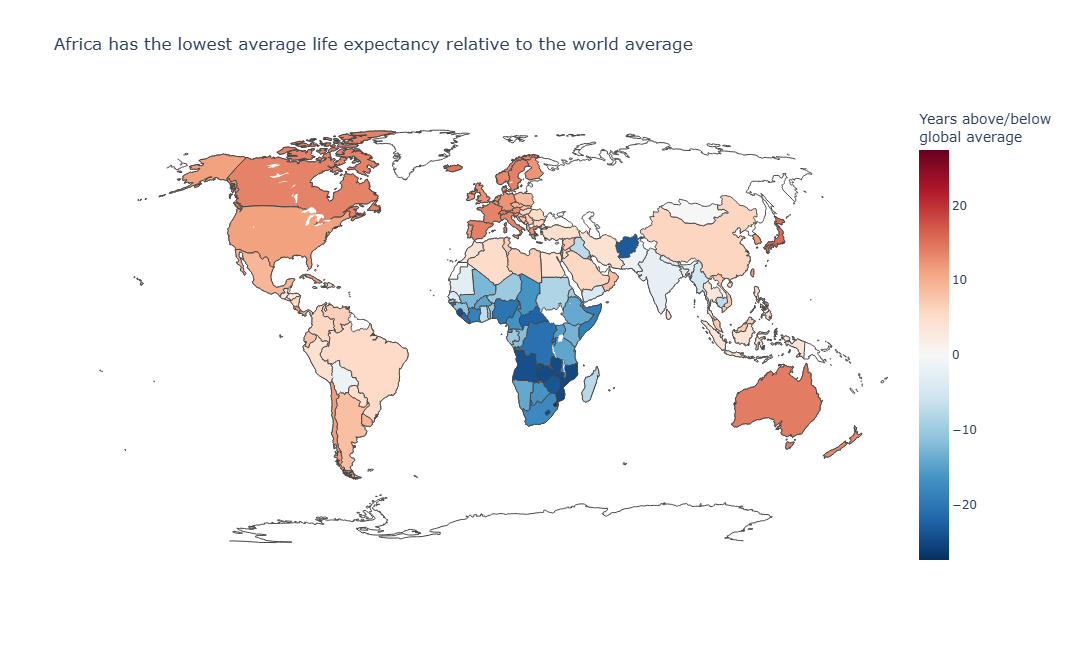

In [4]:
# Task 1
# Load Gapminder dataset
gm = px.data.gapminder()

# Filter data for 2007
gm_2007 = gm[gm['year'] == 2007].copy()

# Calculate global average life expectancy
global_mean = gm_2007['lifeExp'].mean()

# Calculate deviation from global average
gm_2007['deviation'] = gm_2007['lifeExp'] - global_mean

print(f"Global average life expectancy: {global_mean:.2f} years")

# Display countries furthest below average
print(
    gm_2007.sort_values('deviation')
    [['country', 'continent', 'lifeExp', 'deviation']]
    .head(10)
)

continent_deviation = (
    gm_2007.groupby('continent')['deviation']
    .mean()
    .sort_values()
)

print("Average deviation by continent:")
print(continent_deviation)

lowest_continent = continent_deviation.index[0]

print("Region furthest below global average:", lowest_continent)

fig = px.choropleth(
    gm_2007,
    locations='iso_alpha',
    color='deviation',
    hover_name='country',
    hover_data={
        'lifeExp': ':.2f',
        'deviation': ':+.2f',
        'iso_alpha': False
    },
    color_continuous_scale='RdBu_r',
    color_continuous_midpoint=0,
    title=f'{lowest_continent} has the lowest average life expectancy relative to the world average',
    labels={
        'deviation': 'Difference from global average (years)',
        'lifeExp': 'Life Expectancy (years)'
    }
)

fig.update_layout(
    template='plotly_white',
    height=650,
    geo=dict(
        showframe=False,
        showcoastlines=True,
        projection_type='natural earth'
    ),
    coloraxis_colorbar=dict(
        title='Years above/below<br>global average'
    )
)

fig.show()

## Task 2 — Find your own GeoJSON

**What to build:** A choropleth using a GeoJSON file you find yourself online.

**Requirements:**
- Find a free GeoJSON file for any geography that interests you (country, region, city)
- Create or find a matching dataset with at least one numeric variable per region
- Build either a `px.choropleth` or `px.choropleth_mapbox` — state your choice and reason in the markdown cell below
- Correctly identify and set `featureidkey` by inspecting the GeoJSON properties
- Choose sequential or diverging scale — state your reason in the markdown cell below
- Insight title naming a geographic finding

**Where to find GeoJSON files:**
- [geojson.xyz](https://geojson.xyz/) — countries, cities, natural features
- [naturalearthdata.com](https://www.naturalearthdata.com/) — global admin boundaries
- [github.com/datasets/geo-countries](https://github.com/datasets/geo-countries) — country polygons
- Search: `[country name] [admin level] GeoJSON github` — most countries have free boundary files on GitHub

> 💡 Before plotting, always inspect your GeoJSON properties first:
> ```python
> print(my_geojson['features'][0]['properties'])
> ```
> The property name that matches your dataframe's location column is what goes in `featureidkey='properties.???'`


### Task 2 — Design decisions

**GeoJSON source:** https://raw.githubusercontent.com/iamaanahmad/GeoJson-of-Indian-States/master/indian-states.geojson?utm_source=chatgpt.com **

**Chart type chosen** (`px.choropleth` or `px.choropleth_mapbox`) **and reason:**

*px.choropleth. Chosen because it supports external GeoJSON files and allows matching state names using featureidkey='properties.name*

**Colour scale chosen** (sequential or diverging) **and reason:**

*Sequential (YlOrRd). Geographical area is a positive numerical variable, so a sequential colour scale is appropriate. Darker shades indicate larger areas*


In [12]:
# Task 2
# YOUR CODE HERE

import json

# Load GeoJSON using the actual filename
with open('indian-states.geojson', 'r', encoding='utf-8') as file:
    my_geojson = json.load(file)

# Inspect the first feature
print(my_geojson['features'][0]['properties'])

# Extract properties from GeoJSON
india_df = pd.DataFrame([
    feature['properties']
    for feature in my_geojson['features']
])

print(india_df.head())
print("Total regions:", len(india_df))

{'id': 1, 'iso': 'IN-AN', 'name': 'Andaman and Nicobar Islands', 'type': 'Union Territory', 'capital': 'Port Blair', 'area_km2': 8249}
   id    iso                         name             type     capital  \
0   1  IN-AN  Andaman and Nicobar Islands  Union Territory  Port Blair   
1   2  IN-AP               Andhra Pradesh            State   Amaravati   
2   3  IN-AR            Arunachal Pradesh            State    Itanagar   
3   4  IN-AS                        Assam            State      Dispur   
4   5  IN-BR                        Bihar            State       Patna   

   area_km2  
0      8249  
1    160205  
2     83743  
3     78438  
4     94163  
Total regions: 36


In [13]:
# Exclude Union Territories
states_df = india_df[india_df['type'] == 'State'].copy()

# Find largest state
largest_state = states_df.loc[
    states_df['area_km2'].idxmax()
]

print("Largest state:", largest_state['name'])
print("Area:", largest_state['area_km2'], "km²")

Largest state: Rajasthan
Area: 342239 km²


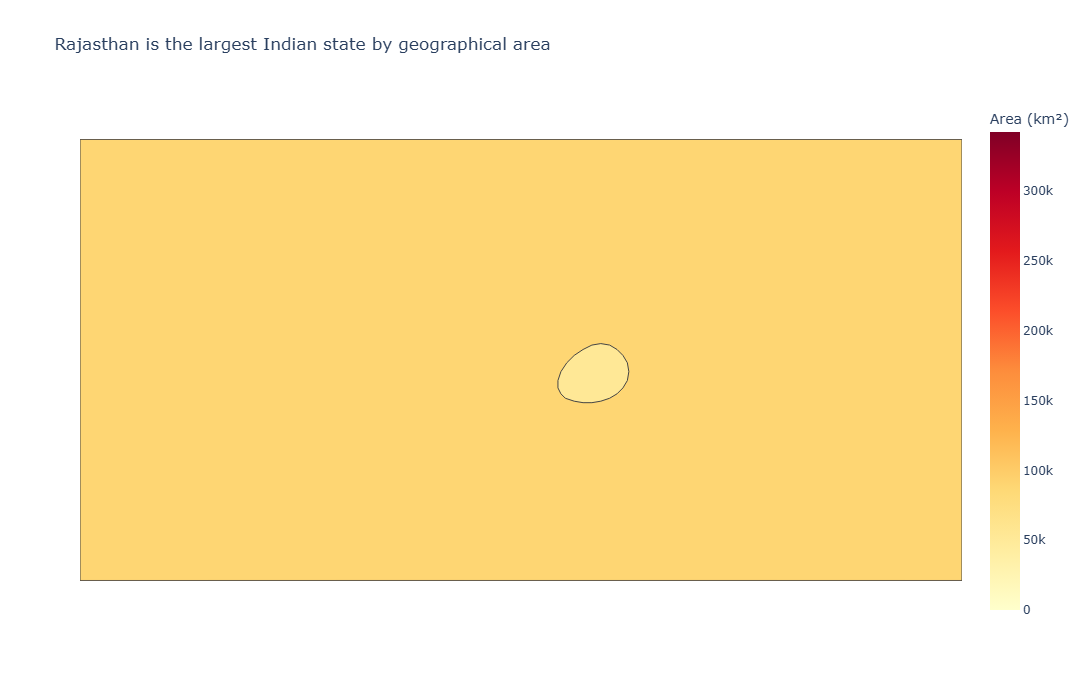

In [14]:
fig = px.choropleth(
    india_df,
    geojson=my_geojson,
    locations='name',
    featureidkey='properties.name',
    color='area_km2',
    hover_name='name',
    hover_data={
        'area_km2': ':.0f',
        'capital': True,
        'type': True
    },
    color_continuous_scale='YlOrRd',
    title='Rajasthan is the largest Indian state by geographical area',
    labels={
        'area_km2': 'Area (km²)'
    }
)

fig.update_geos(
    fitbounds='locations',
    visible=False
)

fig.update_layout(
    template='plotly_white',
    height=700,
    coloraxis_colorbar=dict(title='Area (km²)')
)

fig.show()